## Exercise 8 - K-means clustering

- Use voice.csv file for this exercise set
- This dataset will be used in exercises 8, 9 and 10
- Dataset includes male and female voice samples with different features
- In this exercise you will use unsupervised machine learning method called K-means clustering for the dataset
- **The goal of this exercise is to distinguish male and female voices from the given data**

1 Import all necessary libraries. Then load the dataset and save it to the dataframe.

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn import metrics
import seaborn as sns
from scipy.optimize import linear_sum_assignment
import numpy as np
import os

data = pd.read_csv("data_files/voice.csv", delimiter=",")
voice_data = pd.DataFrame(data)

2 In this exercise you will use only meanfun (*average of fundamental frequency measured across acoustic signal*) and minfun (*minimum fundamental frequency measured across the acoustic signal*) columns. Filter data so that only forementioned columns will be included.

In [42]:
filtered = voice_data[["meanfun", "minfun"]] 
true_labels = voice_data["label"]
filtered.head()

,meanfun,minfun
0,0.084279,0.015702
1,0.107937,0.015826
2,0.098706,0.015656
3,0.088965,0.017798
4,0.106398,0.016931


3 Run the predictions for the data so that it will be categorised for male and female data.

In [43]:
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(filtered)

unique_labels = np.unique(true_labels)

contingency_matrix = metrics.cluster.contingency_matrix(true_labels, cluster_labels)

row_ind, col_ind = linear_sum_assignment(-contingency_matrix)

cluster_to_gender = {c: unique_labels[r] for r, c in zip(row_ind, col_ind)}
filtered['predicted_gender'] = pd.Series(cluster_labels).map(cluster_to_gender)

4 Visualise the data so that clusters for male and female data will be presented in scatter plot (centroids should also be included).

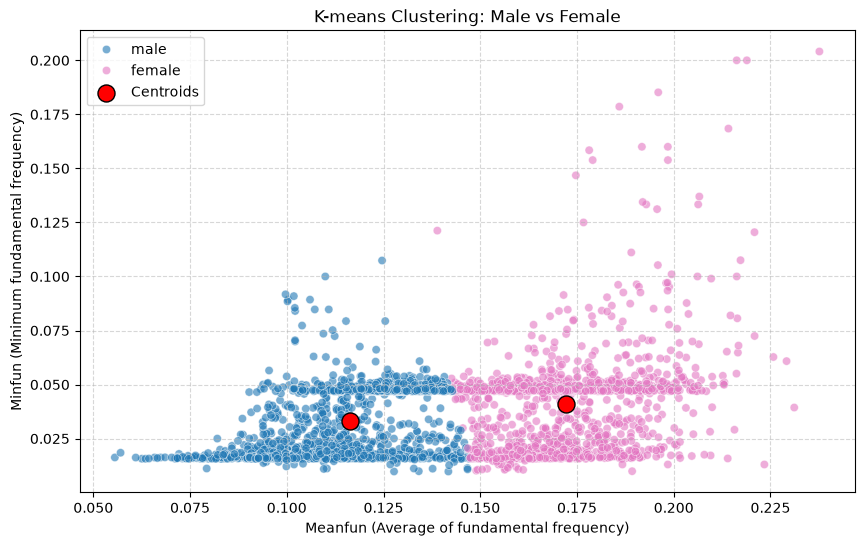

In [44]:
plt.figure(figsize=(10, 6))

import seaborn as sns
sns.scatterplot(
    data=filtered, 
    x='meanfun', 
    y='minfun', 
    hue='predicted_gender', 
    palette={'male': '#1f77b4', 'female': '#e377c2'},
    alpha=0.6
)

centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    s=150, 
    color='red', 
    label='Centroids',
    edgecolor='black'
)

plt.title('K-means Clustering: Male vs Female')
plt.xlabel('Meanfun (Average of fundamental frequency)')
plt.ylabel('Minfun (Minimum fundamental frequency)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

5 Validate K-means clustering prediction results using confusion matrix.

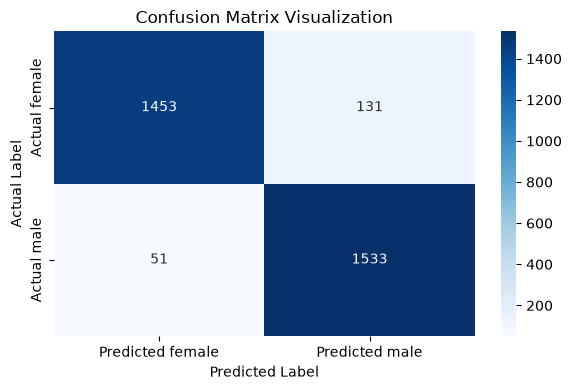

In [45]:
cm = metrics.confusion_matrix(true_labels, filtered['predicted_gender'], labels=unique_labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=[f"Predicted {l}" for l in unique_labels], 
    yticklabels=[f"Actual {l}" for l in unique_labels]
)
plt.title("Confusion Matrix Visualization")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()